# The quality check on real answers

When routing sends a request to a cheaper model, the quality check decides whether the answer is
bad enough to ask the strong model again. A route is proven *together with* this check
(`evaluation/route_proof.py`); this notebook is about the check itself. This notebook answers, with real data:

1. Which signals separate wrong answers from right ones?
2. Which model - from Logistic Regression to a fine-tuned transformer - generalizes best?
3. Is it over- or underfitting, and would more data help?
4. Does an existing LLM as judge do better?
5. What does each threshold cost?

**Data:** answers of the cheaper models (gpt-4o-mini; gpt-4.1-mini on classification) to public
questions with known correct answers (GSM8K, SST-2, MBPP, AG News), labelled by exact scoring,
each with the model's own confidence over the answer text.
Collected live by `evaluation.benchmark --collect`. Questions that prove routes are left out
(`train.training_rows`): the check is measured on those, so it never trains on them.
Every answer is used as an app would receive it (`gate_eval.as_served`: the benchmark's "FINAL:"
marker removed). Every score below is out-of-fold, with folds **grouped by question**: a model is
never scored on a question it saw in training.

In [1]:
import json, logging
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
logging.disable(logging.WARNING)
from evaluation import gate_eval as g, train
from src.paths import DATA_DIR
from src.savings import quality

import yaml
from src.paths import CONFIG_PATH
rows = train.training_rows(yaml.safe_load(CONFIG_PATH.read_text()))
y = np.array([r["label"] for r in rows]); groups = np.array([r["item_id"] for r in rows])
X = g.full_feature_matrix(rows)
kind = train.kinds_of(X)
pd.DataFrame({"kind": kind, "wrong": y == 0}).groupby("kind")["wrong"].agg(answers="count", wrong="sum", share_wrong="mean").round(3)

,answers,wrong,share_wrong
kind,,,
chat,89,50,0.562
classification,600,51,0.085
code,197,38,0.193
reasoning,111,41,0.369


## 1. Baselines and candidates
What a model has to beat: knowing only the kind of question, and the first gate's six
answer-shape features. Then three classic models on all features.

In [2]:
def auc_of(probabilities): return round(roc_auc_score(y, probabilities), 3)
results = {"kind of question only": train.type_only_baseline(rows, X),
           "LogReg, 6 shape features": auc_of(g.grouped_cv_probabilities(g.CANDIDATES["LogisticRegression"], X[:, :6], rows))}
oof = {}
for name in g.SIMPLEST_FIRST:
    oof[name] = g.grouped_cv_probabilities(g.CANDIDATES[name], X, rows)
    results[f"{name}, all features"] = auc_of(oof[name])
pd.Series(results, name="AUC (held-out questions)").to_frame()

,AUC (held-out questions)
kind of question only,0.712
"LogReg, 6 shape features",0.737
"LogisticRegression, all features",0.803
"RandomForest, all features",0.801
"GradientBoosting, all features",0.784


## 2. Over- or underfitting?
Training score against held-out score. A large gap is overfitting (learning the training answers
by heart); two low scores are underfitting (the model or its features are too weak).

In [3]:
rows_fit = []
for name in g.SIMPLEST_FIRST:
    train_auc, test_auc = [], []
    for tr, te in GroupKFold(5).split(X, y, groups):
        m = g.CANDIDATES[name]().fit(X[tr], y[tr])
        train_auc.append(roc_auc_score(y[tr], m.predict_proba(X[tr])[:, 1]))
        test_auc.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    rows_fit.append({"model": name, "train AUC": np.mean(train_auc), "held-out AUC": np.mean(test_auc)})
pd.DataFrame(rows_fit).set_index("model").round(3)

,train AUC,held-out AUC
model,,
LogisticRegression,0.822,0.805
RandomForest,0.985,0.803
GradientBoosting,0.969,0.786


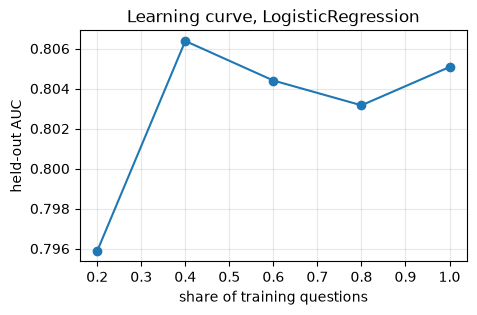

{'20%': 0.796, '40%': 0.806, '60%': 0.804, '80%': 0.803, '100%': 0.805}


In [4]:
# Learning curve of the selected model (the same rule as evaluation/train.py): does more data help?
selected = g.pick_simplest({n: {"auc": results[f"{n}, all features"]} for n in g.SIMPLEST_FIRST})
rng = np.random.default_rng(0); curve = []
for share in (0.2, 0.4, 0.6, 0.8, 1.0):
    aucs = []
    for tr, te in GroupKFold(5).split(X, y, groups):
        questions = np.unique(groups[tr]); keep = set(rng.choice(questions, int(len(questions) * share), replace=False))
        sel = np.isin(groups[tr], list(keep))
        m = g.CANDIDATES[selected]().fit(X[tr][sel], y[tr][sel])
        aucs.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    curve.append((share, np.mean(aucs)))
plt.figure(figsize=(5, 3)); plt.plot(*zip(*curve), marker="o"); plt.xlabel("share of training questions"); plt.ylabel("held-out AUC")
plt.title(f"Learning curve, {selected}"); plt.grid(alpha=.3); plt.show()
print({f"{share:.0%}": round(float(auc), 3) for share, auc in curve})

## 3. Neural networks: can they find their own features?
An MLP on the question and answer embeddings (plus the features), and MiniLM fine-tuned on
(question, answer) as text - a transformer that learns its own features. All candidates read the
same served text, on the answers the judge below also scored, so the numbers compare.

In [5]:
judge = json.loads((DATA_DIR / "gate_eval" / "judge_gpt-4o-mini.json").read_text())
# The judge scored gpt-4o-mini's answers (keyed by question): compare on exactly those answers.
conf_rows = [r for r in rows if r["model"] == "gpt-4o-mini" and r["item_id"] in judge["p_good"]]
yc = np.array([r["label"] for r in conf_rows]); Xc = g.full_feature_matrix(conf_rows)
neural = {"LogReg, all features": g.grouped_cv_probabilities(g.CANDIDATES["LogisticRegression"], Xc, conf_rows),
          "MLP, features + embeddings": g.grouped_cv_probabilities(g.mlp, np.hstack([Xc, g.embedding_matrix(conf_rows)]), conf_rows),
          "fine-tuned MiniLM (own features)": g.finetuned_transformer_cv(conf_rows)}

## 4. An existing model as judge
gpt-4o-mini reads each question and answer and says whether it is correct; its probability of
"yes" is the score. Measured once live (`gate_eval.judge_probabilities`) and stored, so this
notebook makes no API calls.

In [6]:
neural["gpt-4o-mini as judge"] = np.array([judge["p_good"][r["item_id"]] for r in conf_rows])
table = []
for name, p in neural.items():
    m = g.gate_metrics(yc, p, threshold=float(np.quantile(p[yc == 1], 0.10)))
    table.append({"candidate": name, "AUC": m["auc"], "wrong caught at 90% good kept": m["bad_caught"]})
print(f"{len(conf_rows)} answers, {int((yc == 0).sum())} wrong. Judge: about EUR {judge['cost_eur'] / len(judge['p_good']) * len(conf_rows):.4f} for them, one extra call each.")
pd.DataFrame(table).set_index("candidate").round(3)

597 answers, 142 wrong. Judge: about EUR 0.0105 for them, one extra call each.


,AUC,wrong caught at 90% good kept
candidate,,
"LogReg, all features",0.835,0.599
"MLP, features + embeddings",0.739,0.444
fine-tuned MiniLM (own features),0.786,0.493
gpt-4o-mini as judge,0.817,0.289


## 5. The trade-off: what does a threshold cost?
Below the threshold the gate asks the strong model again. A higher threshold catches more wrong
answers, but also sends more good answers to the strong model needlessly - each one an extra call.
The model scores some kinds of question high by nature, so one shared threshold barely fires on
them: the shipped gate has a threshold per kind, each keeping 90% of that kind's good answers.

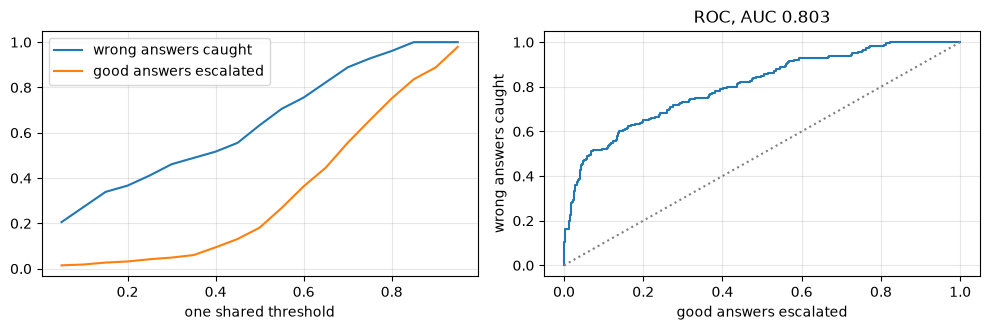

In [7]:
p = oof["LogisticRegression"]
thresholds = np.linspace(0.05, 0.95, 19)
caught = [((p < t) & (y == 0)).sum() / (y == 0).sum() for t in thresholds]
escalated_good = [((p < t) & (y == 1)).sum() / (y == 1).sum() for t in thresholds]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(thresholds, caught, label="wrong answers caught"); ax[0].plot(thresholds, escalated_good, label="good answers escalated")
ax[0].set_xlabel("one shared threshold"); ax[0].legend(); ax[0].grid(alpha=.3)
fpr, tpr, _ = roc_curve(y == 0, 1 - p)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], ":", c="grey"); ax[1].set_xlabel("good answers escalated"); ax[1].set_ylabel("wrong answers caught")
ax[1].set_title(f"ROC, AUC {roc_auc_score(y, p):.3f}"); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

In [8]:
# One shared threshold vs a threshold per kind - both keep 90% of good answers overall
own, default = train.choose_thresholds(y, p, kind)
shared = train.choose_threshold(y, p)
table = []
for k in sorted(set(kind)):
    m = kind == k
    if (y[m] == 0).sum() == 0: continue
    a = g.gate_metrics(y[m], p[m], shared); b = g.gate_metrics(y[m], p[m], own.get(k, default))
    table.append({"kind": k, "wrong": int((y[m] == 0).sum()), "shared: caught": a["bad_caught"], "shared: good kept": a["good_kept"],
                  "per kind: caught": b["bad_caught"], "per kind: good kept": b["good_kept"]})
pd.DataFrame(table).set_index("kind").round(2)

,wrong,shared: caught,shared: good kept,per kind: caught,per kind: good kept
kind,,,,,
chat,50,0.96,0.31,0.96,0.31
classification,51,0.02,0.96,0.26,0.90
code,38,0.29,0.89,0.29,0.90
reasoning,41,0.83,0.73,0.61,0.90


## 6. What the model looks at
Logistic Regression's weights on standardized features: positive pushes towards "good answer".

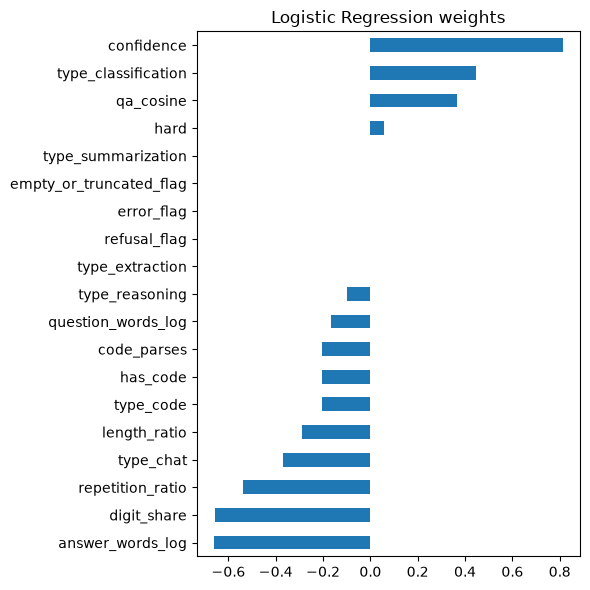

In [9]:
model = g.CANDIDATES["LogisticRegression"]().fit(X, y)  # its weights show which signals matter (see the model card for the shipped model)
weights = pd.Series(model[-1].coef_[0], index=quality.FEATURE_NAMES).sort_values()
weights.plot.barh(figsize=(6, 6), title="Logistic Regression weights"); plt.tight_layout(); plt.show()

## Conclusions

- **Information beats model size.** With the kind of question, format, size and the model's own
  confidence, the classic models generalize best (held-out AUC about 0.80); the selected one
  (`evaluation/train.py`: the simplest within 0.01 AUC of the best) is in `reports/model_card.md`.
- **Fit:** Logistic Regression's training and held-out scores are close (no overfitting); the tree
  models score far higher on their training answers than on new questions (overfitting) - but
  selection is on held-out questions, so that is already priced in. The learning curve is nearly
  flat: more of the same answers adds little - new *signals* would.
- **Neural networks** did not beat the classic models on the 597 gpt-4o-mini answers: the MLP overfits the
  embeddings, and the fine-tuned transformer learns real signal but less. A wrong number in a
  fluent answer looks like a right one to any reader that cannot do the sum.
- **The LLM judge** scores below the classic models and costs an extra call per answer.
- **One threshold for all kinds hides a blind spot** (classification: 8% caught with a shared one).
  That is why each route carries its own threshold, proven on that route's questions.
- **Where it helps, and where not:** on arithmetic it separates right from wrong well; on
  classification - the one live route - it stays near chance even after training on the route's
  own model (gpt-4.1-mini), because a wrong label there is usually a confident one.
- **Limit:** the check reads signs, not truth - a confidently wrong answer passes. So it is never
  trusted on its own: `evaluation/route_proof.py` proves each route *with* the check, on
  questions the check never saw.